In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Temas Selectos de Física Atómica I
## Actividad 1. Evolución Temporal de un Sistema Unidimensional
 Ángel André Aguilar Contreras

In [2]:
class solve:
    def euler(f,t,x0, **kargs): # f es de la forma f(x,t) 
        h , sol = t[1]-t[0] , np.zeros( (len(x0),len(t)) ) # generar una solución de dimensiones (x,t)
        sol[:,0] = x0 # condicion inicial
        for i in range(len(t)-1):
            sol[:,i+1] = sol[:,i] + h*f(sol[:,i],t[i])  # soluciones para cada entrada de x
        return sol

class plot:
    def solution(t, pos, vel, acc):
        fig, axs = plt.subplots(2, 2, figsize=(11, 7), tight_layout=True)

        # Posición vs Tiempo
        axs[0, 0].plot(t, pos, color="navy")
        axs[0, 0].set_ylabel("Posición $x(t)$ [m]")
        axs[0, 0].set_title("Evolución de la Posición")
        axs[0, 0].grid(True, linestyle="--", alpha=0.6)

        # Velocidad vs Tiempo
        axs[0, 1].plot(t, vel, color="darkorange")
        axs[0, 1].set_ylabel("Velocidad $v(t)$ [m/s]")
        axs[0, 1].set_title("Evolución de la Velocidad")
        axs[0, 1].grid(True, linestyle="--", alpha=0.6)

        # Aceleración vs Tiempo
        axs[1, 0].plot(t, acc, color="forestgreen")
        axs[1, 0].set_xlabel("Tiempo $t$ [s]")
        axs[1, 0].set_ylabel("Aceleración $a(t)$ [m/s²]")
        axs[1, 0].set_title("Evolución de la Aceleración")
        axs[1, 0].grid(True, linestyle="--", alpha=0.6)

        # Espacio de Fase (v vs x)
        axs[1, 1].plot(pos, vel, color="purple", lw=1.5)
        axs[1, 1].set_xlabel("Posición $x$ [m]")
        axs[1, 1].set_ylabel("Velocidad $v$ [m/s]")
        axs[1, 1].set_title("Espacio de Fase ($v$ vs $x$)")
        axs[1, 1].grid(True, linestyle="--", alpha=0.6)
        plt.show()

    def multiple_solution(t, POS, VEL, ACC):
        pos_mean, pos_std = np.mean(POS, axis=0), np.std(POS, axis=0)
        vel_mean, vel_std = np.mean(VEL, axis=0), np.std(VEL, axis=0)
        acc_mean, acc_std = np.mean(ACC, axis=0), np.std(ACC, axis=0)

        fig, axs = plt.subplots(2, 2, figsize=(12, 8), tight_layout=True)

        # Posición vs Tiempo
        axs[0, 0].fill_between(t, pos_mean - pos_std, pos_mean + pos_std, color='navy', alpha=0.2, label=r'$\pm 1\sigma$')
        axs[0, 0].plot(t, pos_mean, color='navy', lw=2, label='Promedio')
        axs[0, 0].set_ylabel('Posición $x$ [m]')
        axs[0, 0].set_title('Evolución de la Posición')
        axs[0, 0].grid(True, linestyle='--', alpha=0.5)
        axs[0, 0].legend()

        # Velocidad vs Tiempo
        axs[0, 1].fill_between(t, vel_mean - vel_std, vel_mean + vel_std, color='darkorange', alpha=0.2, label=r'$\pm 1\sigma$')
        axs[0, 1].plot(t, vel_mean, color='darkorange', lw=2, label='Promedio')
        axs[0, 1].set_ylabel('Velocidad $v$ [m/s]')
        axs[0, 1].set_title('Evolución de la Velocidad')
        axs[0, 1].grid(True, linestyle='--', alpha=0.5)
        axs[0, 1].legend()

        # Aceleración vs Tiempo
        axs[1, 0].fill_between(t, acc_mean - acc_std, acc_mean + acc_std, color='forestgreen', alpha=0.2, label=r'$\pm 1\sigma$')
        axs[1, 0].plot(t, acc_mean, color='forestgreen', lw=2, label='Promedio')
        axs[1, 0].set_xlabel('Tiempo $t$ [s]')
        axs[1, 0].set_ylabel('Aceleración $a$ [m/s²]')
        axs[1, 0].set_title('Evolución de la Aceleración')
        axs[1, 0].grid(True, linestyle='--', alpha=0.5)
        axs[1, 0].legend()

        # Espacio de Fase
        for i in range(len(POS)):
            axs[1, 1].plot(POS[i], VEL[i], color='purple', alpha=0.08, lw=0.6)
        axs[1, 1].set_xlabel('Posición $x$ [m]')
        axs[1, 1].set_ylabel('Velocidad $v$ [m/s]')
        axs[1, 1].set_title('Espacio de Fase')
        axs[1, 1].grid(True, linestyle='--', alpha=0.5)
        plt.show()
        
    def histogram(POS, nbins = 25):
        plt.figure(figsize=(8, 5))
        bins = np.linspace(POS[:, 0].min(), POS[:, 0].max(), nbins)

        plt.hist(POS[:,0], bins=bins, alpha=0.5, color='crimson', edgecolor='black', label = 'Inicial')
        plt.hist(POS[:,-1], bins=bins, alpha=0.5, color = 'navy', edgecolor='black', label = 'Final')

        plt.xlabel("Posición [m]")
        plt.ylabel("Número de Partículas")
        plt.title("Comparación de Distribución: Estado Inicial vs. Final")
        plt.legend()
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.show()
                  

In [3]:
def oscilador_amortiguado(x, t, m=1.0, k=10.0, gamma=0.5):
    """
    f(x, t) para un oscilador armónico amortiguado.
    x[0]: Posición
    x[1]: Velocidad
    """
    x1, x2 = x[0], x[1]
    dx1 = x2
    dx2 = -(k / m) * x1 - (gamma / m) * x2
    return np.array([dx1, dx2])

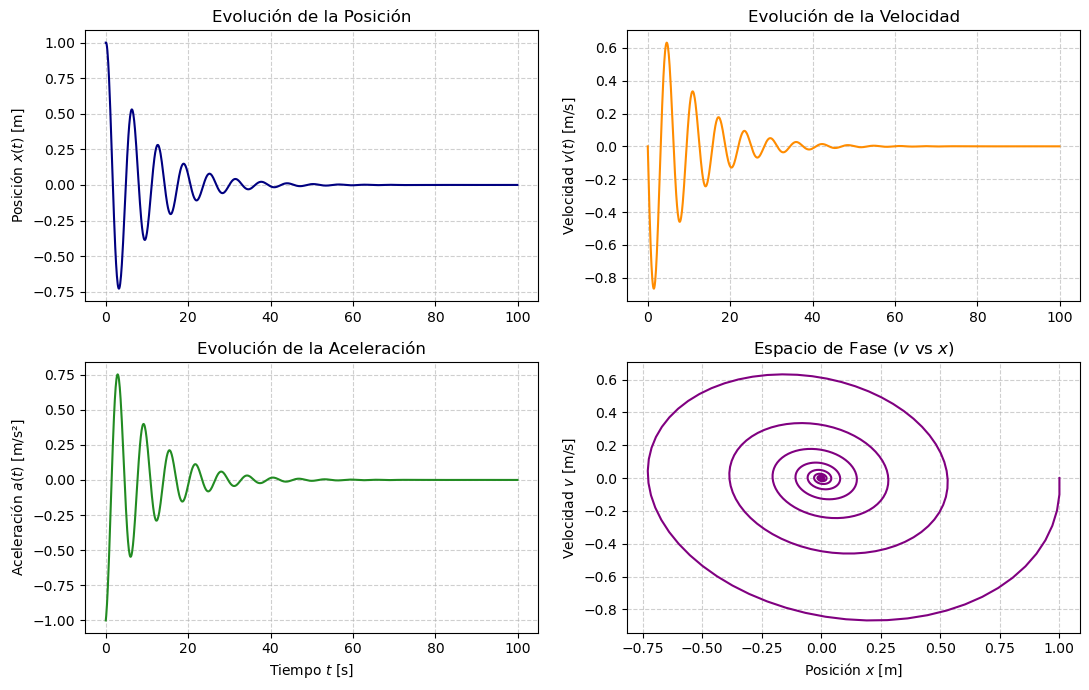

In [4]:
"""
1. Oscilador Armónico Amortiguado Unidimensional para 1 Partícula

Una única partícula de masa m , sujeta a un resorte de constante k y
moviéndose en un medio con amortiguamiento γ. La posición inicial de
la partícula está desplazada una cantidad arbitraria (esta posición debe
ser también un parámetro en el código) respecto al equilibrio y
posteriormente se suelta para observar su movimiento.
"""
# Condiciones iniciales
m = 1.0 # Masa [kg]
k = 1.0 # Constante del resorte
gamma = 0.3 # Amortiguamiento
x0 = np.array([1.0, 0.0])  # Posición inicial [m], Velocidad inicial [m/s]

# Condiciones de Simulación
h = 0.1
t = np.arange(0,100, h) # generación de puntos [s]
f_oscilador = lambda x, t: oscilador_amortiguado(x, t, m=m, k=k, gamma=gamma) # Adaptar la función para que acepte solo (x, t)

# Evolución Temporal
sol = solve.euler(f_oscilador, t, x0)
acc = np.array([f_oscilador(sol[:, i], t[i])[1] for i in range(len(t))])
plot.solution(t, sol[0], sol[1], acc)

In [5]:
"""
2. Oscilador Armónico Amortiguado Unidimensional para un Sistema de Partículas

Un sistema de 100 partículas con la misma masa m y sujeta a resortes
iguales de constante k y moviéndose en un medio con amortiguamiento
γ. La posición inicial de cada partícula sigue una distribución gaussiana
aleatoria.
"""

# Condiciones iniciales
m = 1.0 # Masa [kg]
k = 1.0 # Constante del resorte
gamma = 0.2 # Amortiguamiento

sigma =  np.array([1.0, 1.0]) # Desviación estándar en la posición [m], en la velocidad [m/s]
mu = np.array([1.0, 0.0])  # Posición inicial media [m], Velocidad inicial media [m/s]
particulas = 100 # Cantidad de partículas

X0, V0 = np.random.normal(mu[0], sigma[0], particulas), np.random.normal(mu[1], sigma[1], particulas) 
# Posiciónes y velocidades iniciales siguiendo una distribución gaussiana aleatoria

# Condiciones de Simulación
h = 0.1
t = np.arange(0,100, h) # generación de puntos [s]
f_oscilador = lambda x, t: oscilador_amortiguado(x, t, m=m, k=k, gamma=gamma) # Adaptar la función para que acepte solo (x, t)

# Evolución Temporal
POS, VEL, ACC = [], [], []
for x0, v0 in zip(X0,V0):
    init = np.array([x0, v0])
    sol = solve.euler(f_oscilador, t, init)
    acc = np.array([f_oscilador(sol[:, i], t[i])[1] for i in range(len(t))])
    POS.append(sol[0])
    VEL.append(sol[1])
    ACC.append(acc)

POS = np.array(POS)
VEL = np.array(VEL)
ACC = np.array(ACC)

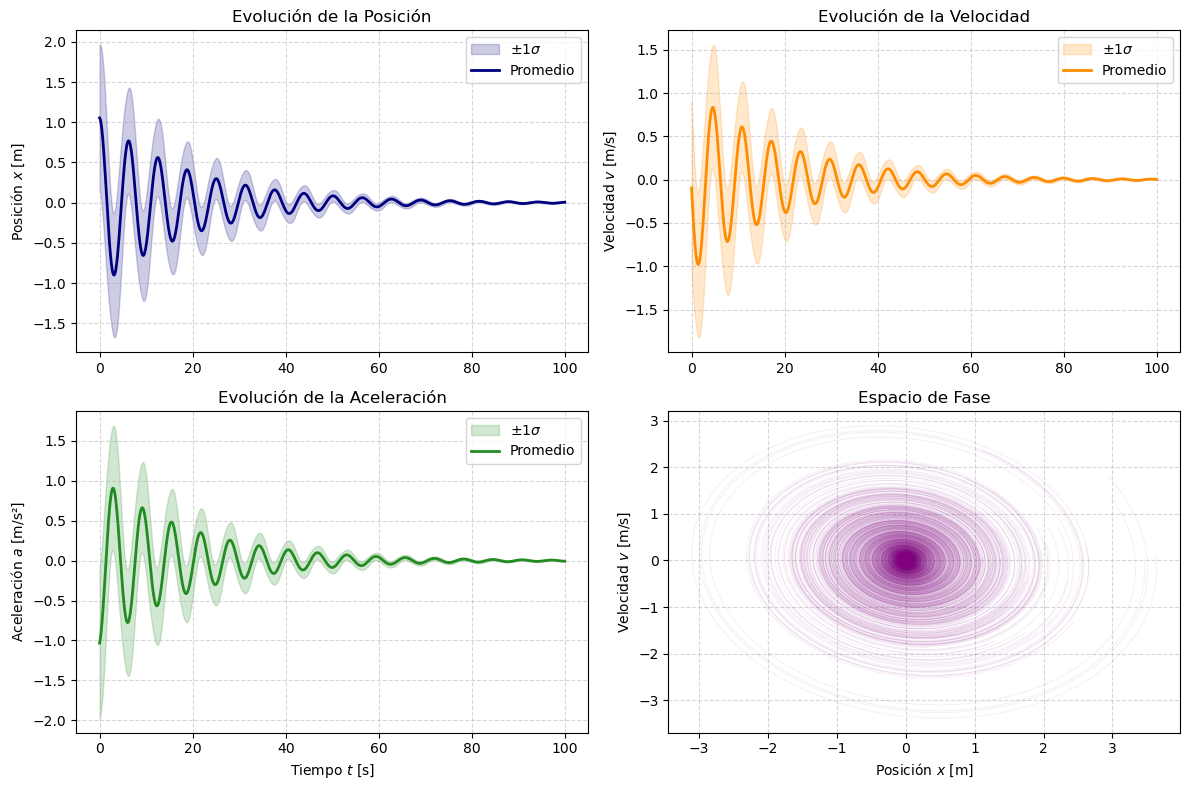

In [6]:
plot.multiple_solution(t, POS, VEL, ACC)

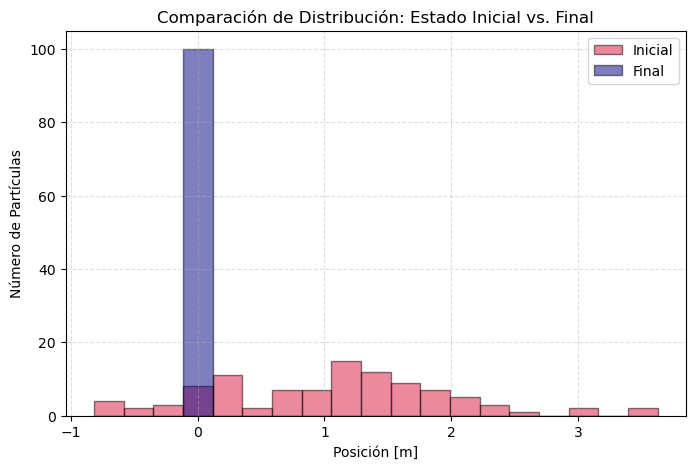

In [7]:
plot.histogram(POS, nbins = 20)